In [2]:
import time

import numpy as np
import matplotlib.pyplot as plt
from scipy.special import pro_ang1

In [3]:

# Experiment parameters
max_order_slep = 35
Nsamples = np.logspace(1, 4, 10).astype(int)
Ntest = 1000
Para_slep = [10]
total_runs = 20
lVal = [0, 0.2, 0.4, 0.6, 0.8, 1]


In [10]:
rng = np.random.default_rng(42)

def samps(n_samples):
    """Generate uniform random samples on [-1, 1]."""
    return rng.uniform(-1, 1, size=int(n_samples))


In [11]:
#This is the function that we approximate
def funct(x, l):
    # t is the variable
    g = np.exp(-0.5*(x-l)**2)


    return g

In [12]:

# Compute Slepian normalization constants

def NorSlep(j, c):
    """Approximate the L2 normalization of a Slepian function."""
    theta = np.linspace(-1, 1, 200)
    pswf_values = pro_ang1(0, j, c, theta)[0]

    theta_interior = theta[1:-1]
    pswf_values = pswf_values[1:-1]

    return np.sqrt(
        0.5 * np.trapezoid(
            np.abs(pswf_values)**2,
            x=theta_interior
        )
    )


# Precompute normalization constants for bandwidth c = 4
norms_ = np.array([
    NorSlep(k, 4)
    for k in range(Para_slep[-1])
])


In [13]:
# Evaluate the normalized Slepian function of degree j
# and bandwidth c at x.

def PSWF(x, j, c):
    pswf_values = pro_ang1(0, j, c, x)[0]
    return pswf_values / norms_[j]

In [14]:

# Construct the least-squares matrix

def Matrix(samp, ordens):
    return np.column_stack([
        PSWF(samp, j, 4)
        for j in range(ordens)
    ])


In [15]:

# Compute test errors for different Gaussian centers l

MSE_slep = np.zeros(
    (len(lVal), len(Para_slep), len(Nsamples), total_runs)
)

start_time = time.time()
total_iterations = len(lVal) * total_runs * len(Para_slep) * len(Nsamples)
counter = 0

for il, l in enumerate(lVal):
    for run in range(total_runs):

        # Generate training data
        SamSet = samps(Nsamples[-1])
        y_train = funct(SamSet, l)

        # Construct the training matrix (bandwidth c = 4)
        A = Matrix(SamSet, Para_slep[-1])

        # Generate test data
        TestSet = samps(Ntest)
        y_test = funct(TestSet, l)

        # Construct the test matrix
        A_test = Matrix(TestSet, Para_slep[-1])

        for orde, order in enumerate(Para_slep):
            for k, n_samples in enumerate(Nsamples):

                A_s = A[:n_samples, :order]
                y_s = y_train[:n_samples]
                A_test_s = A_test[:, :order]

                # Solve the least-squares problem
                coeffs = np.linalg.lstsq(A_s, y_s, rcond=None)[0]

                # Evaluate on the test set
                y_pred = A_test_s @ coeffs
                error = np.linalg.norm(y_pred - y_test) / np.sqrt(Ntest)

                MSE_slep[il, orde, k, run] = error

                # Report progress
                counter += 1
                elapsed = time.time() - start_time
                remaining = (total_iterations - counter) * elapsed / counter

                print(
                    f"l={l}, error={error:.6g}, "
                    f"progress={100 * counter / total_iterations:.2f}%, "
                    f"approximately {remaining:.1f} seconds remaining"
                )


l=0, error=6.43228e-07, progress=0.08%, approximately 2353.9 seconds remaining
l=0, error=8.08293e-08, progress=0.17%, approximately 1176.1 seconds remaining
l=0, error=4.05518e-08, progress=0.25%, approximately 783.5 seconds remaining
l=0, error=2.19099e-08, progress=0.33%, approximately 587.7 seconds remaining
l=0, error=1.43295e-08, progress=0.42%, approximately 469.8 seconds remaining
l=0, error=1.30376e-08, progress=0.50%, approximately 391.2 seconds remaining
l=0, error=1.22054e-08, progress=0.58%, approximately 335.1 seconds remaining
l=0, error=1.21778e-08, progress=0.67%, approximately 292.9 seconds remaining
l=0, error=1.21374e-08, progress=0.75%, approximately 260.2 seconds remaining
l=0, error=1.21148e-08, progress=0.83%, approximately 234.1 seconds remaining
l=0, error=3.27264e-07, progress=0.92%, approximately 423.2 seconds remaining
l=0, error=4.20168e-08, progress=1.00%, approximately 387.7 seconds remaining
l=0, error=1.45401e-08, progress=1.08%, approximately 357.5 se

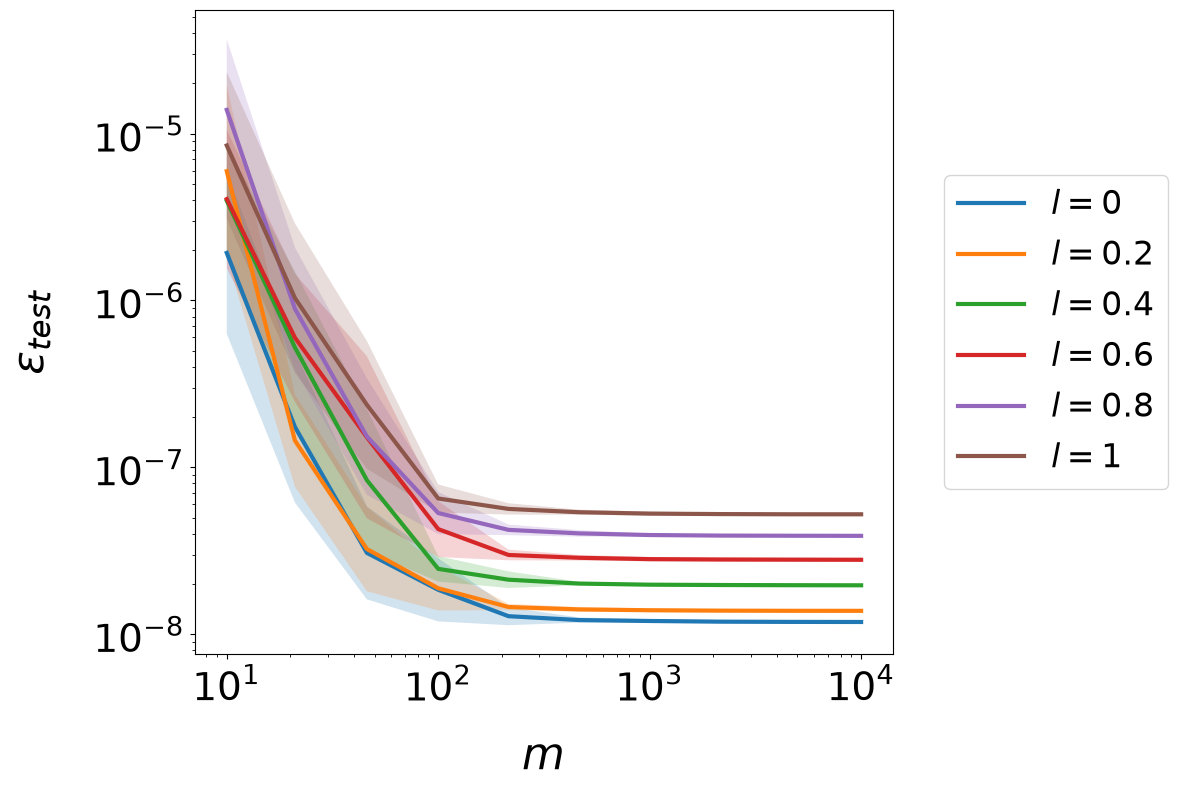

In [17]:

# Plot error over training set sizes
plt.figure(figsize=(12, 8))

for il, l in enumerate(lVal):

    # Average over runs
    results_mean = np.mean(MSE_slep[il], axis=2)

    # Relative standard deviation over runs
    results_lower = np.std(MSE_slep[il], axis=2) / results_mean

    # Since Para_slep = [10], there is only one curve
    i = 0

    plt.loglog(
        Nsamples,
        results_mean[i, :],
        label=fr"$l={l}$",
        linewidth=3
    )

    plt.fill_between(
        Nsamples,
        results_mean[i, :] / (1 + results_lower[i, :]),
        results_mean[i, :] * (1 + results_lower[i, :]),
        alpha=0.2
    )

plt.xlabel(r'$m$', fontsize=32, labelpad=18)
plt.ylabel(r'$\epsilon_{test}$', fontsize=32, labelpad=28)

plt.tick_params(axis='both', which='major', labelsize=28)
plt.tick_params(axis='both', which='minor', labelsize=28)

plt.legend(
    fontsize=24,
    loc='center left',
    bbox_to_anchor=(1.05, 0.5),
    ncol=1
)

plt.tight_layout()

plt.savefig("translated_exponential.pdf", bbox_inches="tight")
plt.show()
